# DATA UNDERSTANDING

### Import the Dependencies

In [1]:
# Image Processing Tools
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
from PIL import Image
# Plot and Graph
import matplotlib.pyplot as plt
import seaborn as sns
# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.math import confusion_matrix

In [ ]:
tf.random.set_seed(3)
sns.set_style('whitegrid')

### Import the Dataset

In [ ]:
from keras.datasets import mnist

In [4]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Exploratory Data Analysis

In [5]:
type(X_train)

numpy.ndarray

In [ ]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

Training data = 60,000 images

Test data = 10,000 images

Images Dimension = 28x28

Grayscale Image = 1 channel

In [ ]:
X_train[23]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0, 121, 254, 136,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [ ]:
X_train[23].shape

(28, 28)

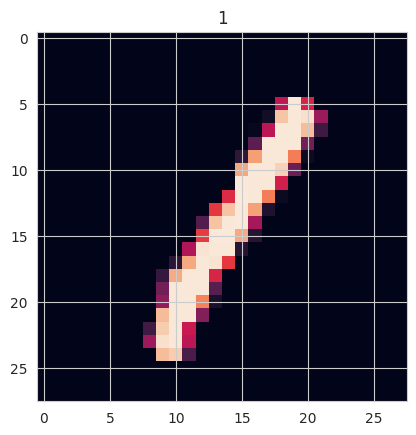

In [9]:
# Display the image
plt.imshow(X_train[23])
plt.title(y_train[23])
plt.show()

In [ ]:
# Unique values in y_train
print(np.unique(y_train))
# Unique values in y_test
print(np.unique(y_test))

[0 1 2 3 4 5 6 7 8 9]
[0 1 2 3 4 5 6 7 8 9]


# DATA PREPARATION

### Feature Scaling

In [11]:
# Scaling the values
X_train = X_train/255
X_test = X_test/255

In [12]:
X_train[23]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

# MODELING

### Build the NN

In [13]:
# Setting the layers
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Compile the NN

In [14]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### Train the NN

In [15]:
model.fit(X_train, y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9109 - loss: 0.3026
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9584 - loss: 0.1401
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9692 - loss: 0.1037
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9754 - loss: 0.0819
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9798 - loss: 0.0671
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9828 - loss: 0.0562
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9857 - loss: 0.0475
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9874 - loss: 0.0413
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9891 - loss: 0.0364
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9902 - loss: 0.0324


### Save the Model

In [16]:
model.save('handwritted_digit_clf.keras')

# MODEL EVALUATION

In [17]:
# Accuracy
loss, accuracy = model.evaluate(X_test, y_test)
accuracy

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9726 - loss: 0.1089


0.972599983215332

Test data accuracy = 96.8%

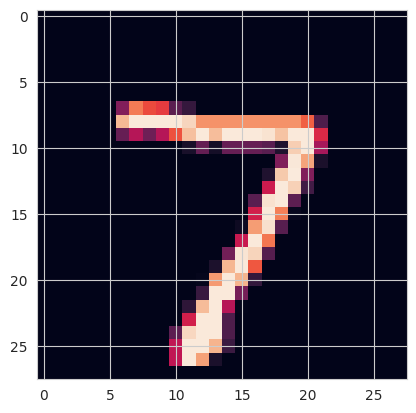

In [18]:
plt.imshow(X_test[0]);

In [19]:
print(y_test[0])

7


In [20]:
y_test.shape

(10000,)

### Make a Prediction

In [21]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [22]:
print(y_pred[0])

[1.9217575e-02 7.5504096e-05 5.3755760e-02 4.5239136e-01 1.2628462e-07
 1.9519622e-02 1.8172071e-09 1.0000000e+00 2.3469637e-04 4.3971965e-01]


In [23]:
y_pred.shape

(10000, 10)

In [24]:
# Convert the predict proba to class label
np.argmax(y_pred[0])

np.int64(7)

In [25]:
y_pred_label = [np.argmax(i) for i in y_pred]

In [26]:
y_pred_label[0]

np.int64(7)

In [27]:
print(y_pred)

[[1.92175750e-02 7.55040965e-05 5.37557602e-02 ... 1.00000000e+00
  2.34696374e-04 4.39719647e-01]
 [6.13343764e-06 1.81707188e-01 1.00000000e+00 ... 2.76094668e-11
  6.50632521e-03 1.01671784e-13]
 [1.74584475e-05 9.99629259e-01 1.96357965e-02 ... 6.32494628e-01
  2.69291680e-02 3.69355897e-04]
 ...
 [2.53685073e-07 5.96165890e-03 3.63703002e-05 ... 5.00322938e-01
  2.66184598e-01 9.36433613e-01]
 [9.04083117e-06 8.34398772e-09 3.09825882e-05 ... 7.35226013e-09
  9.98169661e-01 9.00985299e-07]
 [5.31485379e-01 1.08762821e-08 1.92365248e-03 ... 1.29479080e-10
  6.12775348e-02 2.41490920e-06]]


### Confusion Matrix

In [28]:
conf_mat = confusion_matrix(y_test, y_pred_label)

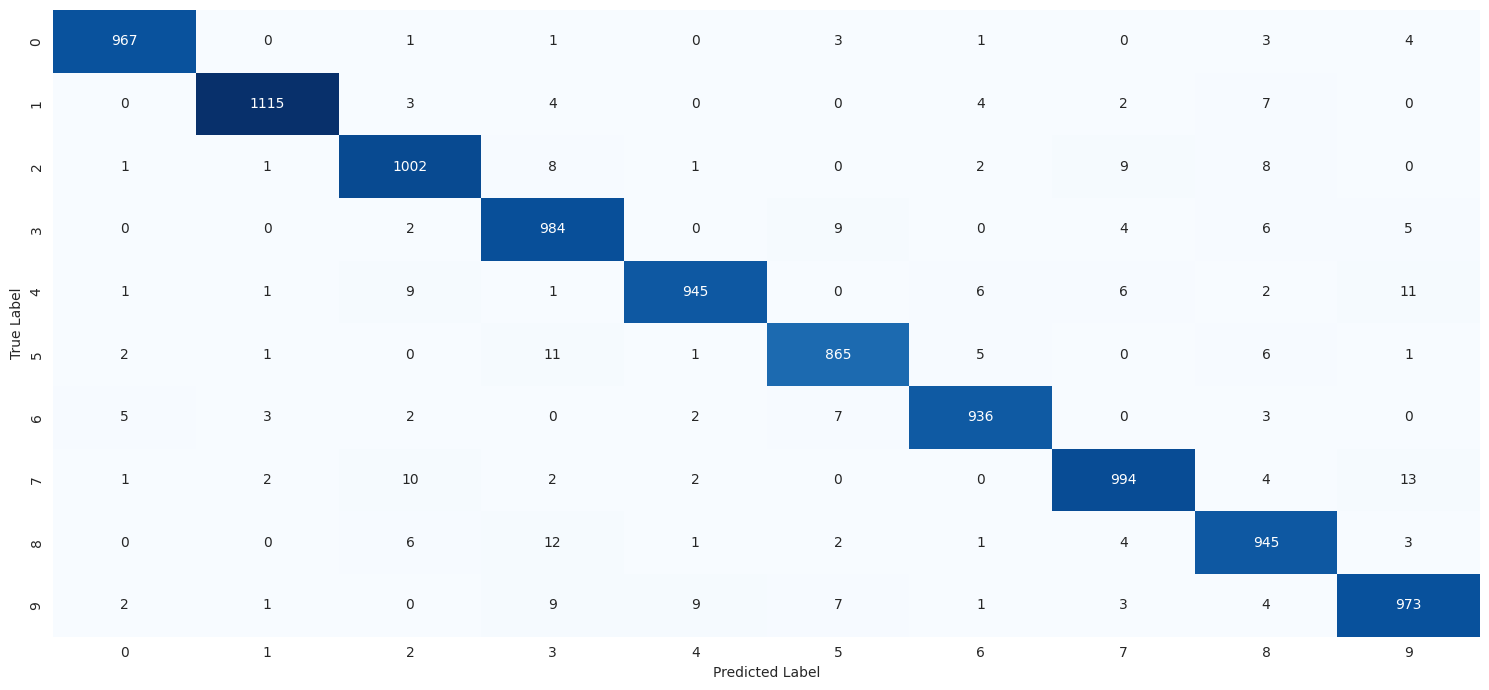

In [29]:
plt.figure(figsize=(15,7))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Predictive System

### Step by Step so we can understanding the flow

In [30]:
!wget 'https://imgs.search.brave.com/k1P2Rz_MUrS6XclJFya5jneoMrnh2iC8H59n-SpSv14/rs:fit:860:0:0:0/g:ce/aHR0cHM6Ly90My5m/dGNkbi5uZXQvanBn/LzE2Lzg4Lzc5Lzg0/LzM2MF9GXzE2ODg3/OTg0OTRfbDBhMWlF/dUlXMTJ5bkdnWmh6/aEExU2x5T0tMTEtK/Z1QuanBn'
!wget 'https://imgs.search.brave.com/yLIz01DrKxA1dj_QL_Kmn2iGtftmR66y7_5Gixg7Iww/rs:fit:860:0:0:0/g:ce/aHR0cHM6Ly9jZG4u/dWwucnVuL2V1L3Qv/ZDNhNzczNmIwNGQ4/MGU5ZTc3OTI4Y2Y1/NmY5OTFmNDNfMjU2/LndlYnA_RXhwaXJl/cz0xNzkyMjcwODAw/JktleU5hbWU9a2V5/LXYxJlNpZ25hdHVy/ZT1qU3hvNXB1M0Ff/ME12d1ZHS003cUt2/YV9BTU0'

--2026-10-17 18:21:39--  https://imgs.search.brave.com/k1P2Rz_MUrS6XclJFya5jneoMrnh2iC8H59n-SpSv14/rs:fit:860:0:0:0/g:ce/aHR0cHM6Ly90My5m/dGNkbi5uZXQvanBn/LzE2Lzg4Lzc5Lzg0/LzM2MF9GXzE2ODg3/OTg0OTRfbDBhMWlF/dUlXMTJ5bkdnWmh6/aEExU2x5T0tMTEtK/Z1QuanBn
Resolving imgs.search.brave.com (imgs.search.brave.com)... 13.249.182.20, 13.249.182.50, 13.249.182.107, ...
Connecting to imgs.search.brave.com (imgs.search.brave.com)|13.249.182.20|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5984 (5.8K) [image/jpeg]
Saving to: ‘Z1QuanBn’

Z1QuanBn            100%[===================>]   5.84K  --.-KB/s    in 0s      

2026-10-17 18:21:39 (241 MB/s) - ‘Z1QuanBn’ saved [5984/5984]

--2026-10-17 18:21:39--  https://imgs.search.brave.com/yLIz01DrKxA1dj_QL_Kmn2iGtftmR66y7_5Gixg7Iww/rs:fit:860:0:0:0/g:ce/aHR0cHM6Ly9jZG4u/dWwucnVuL2V1L3Qv/ZDNhNzczNmIwNGQ4/MGU5ZTc3OTI4Y2Y1/NmY5OTFmNDNfMjU2/LndlYnA_RXhwaXJl/cz0xNzkyMjcwODAw/JktleU5hbWU9a2V5/LXYxJlNpZ25hdHVy/ZT1qU3hvNXB1M0Ff/ME12d1ZHS00

In [35]:
input_image = cv2.imread('digit.jpg')

In [36]:
type(input_image)

numpy.ndarray

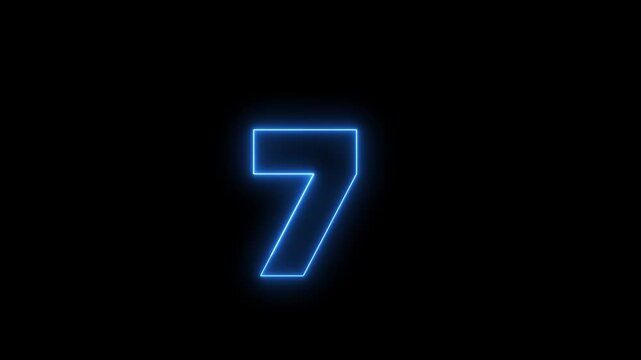

In [37]:
cv2_imshow(input_image)

In [38]:
input_image.shape

(360, 641, 3)

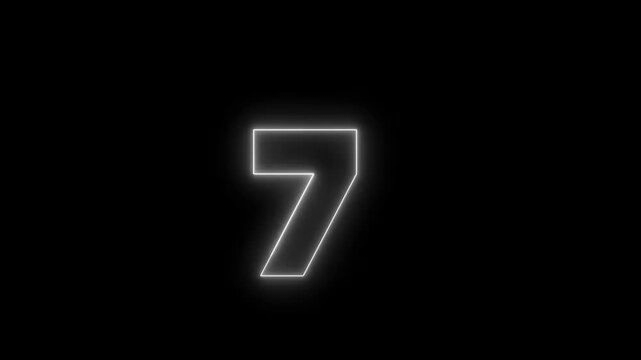

(360, 641)

In [39]:
grayscaled = cv2.cvtColor(input_image, cv2.COLOR_RGB2GRAY)
cv2_imshow(grayscaled)
grayscaled.shape

In [40]:
resized = cv2.resize(grayscaled, (28,28))
cv2_imshow(resized)
resized.shape

(28, 28)

In [41]:
resized = resized/255

In [42]:
reshaped_img = np.reshape(resized, [1,28,28])

In [43]:
input_pred = model.predict(reshaped_img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step


In [44]:
input_pred_label = np.argmax(input_pred)

In [45]:
input_pred_label

np.int64(4)

### Final Predictive System

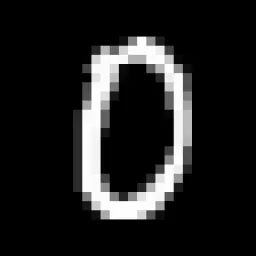

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
The handwrited digit is: 0


In [49]:
input_path = input('Image path you want to predict: ')
image = cv2.imread(input_path)
cv2_imshow(image)
grayscaled_img = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
resized_img = cv2.resize(grayscaled_img, (28,28))
scaled_img = resized_img/255
reshaped_img = np.reshape(scaled_img, [1,28,28])
predict = model.predict(reshaped_img)
predict_label = np.argmax(predict)
print('The handwrited digit is:', predict_label)